# Lab 3.3 — Implicit and Explicit Reasoning in Language Models
**Course:** AI Agents · **Unit:** LLMs as the agent's brain · **Platform:** Google Colab — **GPU T4 required** (`Runtime → Change runtime type → T4 GPU`)

When a language model answers a question that needs several steps, the reasoning can happen in two places:

| | **Implicit reasoning** | **Explicit reasoning** |
|---|---|---|
| Where | Inside the network: hidden states of the forward passes that produce the answer tokens | In the generated text: intermediate steps written as tokens (*chain of thought*) |
| Compute used | Fixed: one forward pass per answer token (an answer like "18" gets only 2–3 passes) | Grows with the length of the reasoning: every written token is one more forward pass |
| Memory | Only the activations inside each pass | The written tokens become a **scratchpad** the model can read back |
| Inspectable? | No | Yes — but the written steps are not guaranteed to be the "real" cause of the answer |
| Cost | Few tokens, fast | Many tokens, slower and more expensive |

A useful analogy is Kahneman's *System 1* (fast, intuitive) and *System 2* (slow, deliberate). In LLMs we can **move from implicit to explicit reasoning** with two families of tools, which are the two parts of this lab:

- **Part A — by prompts:** we ask for a direct answer, or ask the model to think step by step, show it worked examples, or give it a plan to follow.
- **Part B — by prompts and LLM parameters:** the same prompts combined with decoding settings — the **token budget** (`max_new_tokens`), **temperature / top-p** (Lab 2.5), **sampling many reasoning paths** and voting (self-consistency), and the **thinking switch** of a modern reasoning model.

This is a **guided lab**: all code is provided. Run each cell, read the outputs, change the prompts and values when invited, and answer the questions in Part C.

### Learning objectives
1. Explain the difference between implicit and explicit reasoning and why explicit reasoning gives the model more computation.
2. Compare prompting strategies (direct, zero-shot CoT, few-shot CoT, plan-and-solve, answer-first) on accuracy **and** token cost.
3. Measure how the token budget, temperature and the number of sampled paths change the benefit of explicit reasoning.
4. Choose a reasoning configuration for an agent, considering accuracy, cost and reliability.

| Part | Topic | Experiments |
|---|---|---|
| 0 | Setup, problem set and helpers | – |
| 1 | System 1 vs System 2 on one problem | 1 |
| A | Implicit → explicit **by prompts** | A1, A2, A3 |
| B | Implicit → explicit **by prompts + parameters** | B1, B2, B3, B4 (optional) |
| C | Questions | – |

## Part 0 — Setup
We use **`Qwen/Qwen2.5-1.5B-Instruct`** (open weights, Apache 2.0, no Hugging Face login needed). It is small enough for a free T4 GPU and strong enough to solve grade-school math problems when it reasons explicitly — and to fail several of them when it answers directly. On CPU the notebook automatically falls back to the 0.5B version.

In [ ]:
%pip install -q -U transformers accelerate

In [ ]:
import math
import random
import re
import textwrap
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import logging as hf_logging
from transformers import set_seed as hf_set_seed

hf_logging.set_verbosity_error()          # hide warnings about unused generation flags
pd.set_option("display.max_colwidth", 120)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); hf_set_seed(seed)

set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if device == "cuda" else torch.float32
print("PyTorch", torch.__version__, "| device:", device)
if device == "cpu":
    print("⚠️ No GPU found: switch to a T4 runtime for reasonable speed. Falling back to the 0.5B model.")

PyTorch 2.11.0+cu130 | device: cuda


In [ ]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct" if device == "cuda" else "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, padding_side="left")   # left padding for batched generation
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE).to(device).eval()
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct: 1.54B parameters


### Generation helper
`generate` sends a **batch** of chat conversations to the model and returns, for each conversation, a list of `n` outputs (text and number of generated tokens). Every decoding parameter is passed explicitly, so the model's own defaults never interfere (see Lab 2.5):
- `temperature = 0` → greedy decoding (deterministic);
- `temperature > 0` → sampling with the given `top_p` / `top_k`;
- `repetition_penalty` is always 1 (off).

`chat_kwargs` is passed to the chat template; we will use it in Experiment B4 to switch a reasoning model's *thinking mode* on and off.

In [ ]:
def chat_text(messages, tok=None, chat_kwargs=None):
    # Conversation → raw prompt string, ending where the assistant starts to write.
    tok = tok or tokenizer
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, **(chat_kwargs or {}))

@torch.no_grad()
def generate(conversations, max_new_tokens=256, temperature=0.0, top_p=1.0, top_k=0, n=1,
             seed=SEED, batch_size=12, mdl=None, tok=None, chat_kwargs=None):
    mdl, tok = mdl or model, tok or tokenizer
    set_seed(seed)
    prompts = [chat_text(c, tok, chat_kwargs) for c in conversations]
    if temperature > 0:
        sampling = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=top_k)
    else:
        sampling = dict(do_sample=False)
    results = []
    for b in range(0, len(prompts), batch_size):
        enc = tok(prompts[b:b + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(mdl.device)
        out = mdl.generate(**enc, max_new_tokens=max_new_tokens, num_return_sequences=n,
                           repetition_penalty=1.0, pad_token_id=tok.pad_token_id, **sampling)
        new_tokens = out[:, enc.input_ids.shape[1]:]
        for i in range(new_tokens.shape[0] // n):
            group = []
            for g in new_tokens[i * n:(i + 1) * n]:
                ids = g[g != tok.pad_token_id].tolist()
                text = tok.decode(ids, skip_special_tokens=True).strip()
                group.append({"text": text, "ids": ids, "n_tokens": len(ids)})
            results.append(group)
    return results

print(generate([[{"role": "user", "content": "In one sentence: what is chain-of-thought prompting?"}]], max_new_tokens=60)[0][0]["text"])

Chain-of-thought prompting is a technique in AI that involves generating multiple possible solutions to a problem and then selecting the most appropriate one based on a set of criteria.


### The problem set
Twelve multi-step word problems with a single numeric answer (grade-school level, in the style of the GSM8K benchmark). Each one needs 2–4 operations. Problem **P12** is a classic "intuition trap" for humans: the fast answer is wrong.

👉 **Try it:** you can add your own problems — just keep a numeric `answer`.

In [ ]:
PROBLEMS = [
    {"id": "P01", "answer": 18,  "question": "A bakery makes 24 muffins in each batch. On Monday it bakes 7 batches and sells 150 muffins. How many muffins are left?"},
    {"id": "P02", "answer": 33,  "question": "Ana has 3 times as many stickers as Luis. Luis has 14 stickers. Ana gives 9 of her stickers to Luis. How many stickers does Ana have now?"},
    {"id": "P03", "answer": 290, "question": "A train travels at 80 km/h for 2.5 hours and then at 60 km/h for 1.5 hours. How many kilometers does it travel in total?"},
    {"id": "P04", "answer": 25,  "question": "A shirt costs $40. It is discounted by 25%, and then a $5 coupon is applied to the discounted price. What is the final price in dollars?"},
    {"id": "P05", "answer": 8,   "question": "A farmer has only chickens and cows. Together they have 20 heads and 56 legs. How many cows does the farmer have?"},
    {"id": "P06", "answer": 18,  "question": "Maria reads 12 pages per day. Her book has 300 pages and she has already read 84 pages. How many more days does she need to finish the book?"},
    {"id": "P07", "answer": 750, "question": "A water tank holds 1200 liters when full. It is 3/4 full. Then 250 liters are used and 100 liters are added. How many liters are in the tank now?"},
    {"id": "P08", "answer": 16,  "question": "Carlos is 4 years older than his sister. In 6 years, the sum of their ages will be 40. How old is Carlos now?"},
    {"id": "P09", "answer": 150, "question": "A rectangle has a perimeter of 50 cm and a length of 15 cm. What is its area in square centimeters?"},
    {"id": "P10", "answer": 32,  "question": "A store sells pens only in packs of 6 for $4 per pack. How many dollars do you need to buy at least 45 pens?"},
    {"id": "P11", "answer": 10,  "question": "In a class of 32 students, 3/8 play football. Half of the remaining students play basketball. How many students play neither sport?"},
    {"id": "P12", "answer": 5, "also": [0.05], "question": "A bat and a ball cost $1.10 in total. The bat costs $1.00 more than the ball. How many cents does the ball cost?"},
]

display(pd.DataFrame(PROBLEMS).set_index("id")[["question", "answer"]])

,question,answer
id,,
P01,A bakery makes 24 muffins in each batch. On Monday it bakes 7 batches and sells 150 muffins. How many muffins are left?,18
P02,Ana has 3 times as many stickers as Luis. Luis has 14 stickers. Ana gives 9 of her stickers to Luis. How many sticke...,33
P03,A train travels at 80 km/h for 2.5 hours and then at 60 km/h for 1.5 hours. How many kilometers does it travel in to...,290
P04,"A shirt costs $40. It is discounted by 25%, and then a $5 coupon is applied to the discounted price. What is the fin...",25
P05,A farmer has only chickens and cows. Together they have 20 heads and 56 legs. How many cows does the farmer have?,8
P06,Maria reads 12 pages per day. Her book has 300 pages and she has already read 84 pages. How many more days does she ...,18
P07,A water tank holds 1200 liters when full. It is 3/4 full. Then 250 liters are used and 100 liters are added. How man...,750
P08,"Carlos is 4 years older than his sister. In 6 years, the sum of their ages will be 40. How old is Carlos now?",16
P09,A rectangle has a perimeter of 50 cm and a length of 15 cm. What is its area in square centimeters?,150


### Reading the final answer
To grade an output we need to extract its final number. All prompts ask the model to finish with `Answer: <number>`; the extractor looks for that pattern first, then for a LaTeX `\boxed{...}` (Qwen likes it), and finally for any number. `which="first"` is used by the *answer-first* prompt, where the answer is at the beginning.

The small checks below show what the extractor does.

In [ ]:
NUM = r"-?\d[\d,]*(?:\.\d+)?"

def _to_float(s):
    return float(s.replace(",", ""))

def extract_answer(text, which="last"):
    # Number after 'Answer:' / 'the answer is'; else inside \boxed{}; else any number. `which`: first or last match.
    t = text.replace("$", "").replace("**", "")
    for pattern in (r"answer\s*(?:is)?\s*[:=]?\s*(" + NUM + ")", r"\\boxed\{\s*(" + NUM + ")", "(" + NUM + ")"):
        matches = re.findall(pattern, t, flags=re.IGNORECASE)
        if matches:
            return _to_float(matches[0] if which == "first" else matches[-1])
    return None

def is_correct(pred, problem):
    if pred is None:
        return False
    golds = [problem["answer"]] + problem.get("also", [])
    return any(abs(pred - g) < 1e-6 for g in golds)

def has_final_answer(text):
    return bool(re.search(r"answer\s*(?:is)?\s*[:=]?\s*\**\s*\$?\s*-?\d|\\boxed\{", text, flags=re.IGNORECASE))

def majority_vote(preds):
    # Most frequent valid answer and its agreement (fraction of valid votes).
    valid = [p for p in preds if p is not None]
    if not valid:
        return None, 0.0
    answer, count = Counter(valid).most_common(1)[0]
    return answer, count / len(valid)

def cut_before_final_answer(text):
    # Reasoning part of an explicit answer: everything before the last 'Answer' / 'final answer' / '\boxed'.
    matches = list(re.finditer(r"(?:final\s+)?answer|\\boxed", text, flags=re.IGNORECASE))
    reasoning = text[:matches[-1].start()] if matches else text
    return reasoning.rstrip(" *#:\n\t")

for t in ["Answer: 18", "So 24 x 7 = 168 and 168 - 150 = 18.\n**Answer: 18**", "The answer is $25.00.",
          "Thus the area is \\boxed{150}.", "Answer: 10\nBecause the ball costs 10 cents...", "I am not sure."]:
    print(f"{t!r:70} → last: {extract_answer(t)}   first: {extract_answer(t, 'first')}")

'Answer: 18'                                                           → last: 18.0   first: 18.0
'So 24 x 7 = 168 and 168 - 150 = 18.\n**Answer: 18**'                  → last: 18.0   first: 18.0
'The answer is $25.00.'                                                → last: 25.0   first: 25.0
'Thus the area is \\boxed{150}.'                                       → last: 150.0   first: 150.0
'Answer: 10\nBecause the ball costs 10 cents...'                       → last: 10.0   first: 10.0
'I am not sure.'                                                       → last: None   first: None


## Part 1 — System 1 vs System 2 on one problem
## Experiment 1 — the bat and the ball
> *A bat and a ball cost \$1.10 in total. The bat costs \$1.00 more than the ball. How many cents does the ball cost?*

Most people answer **10 cents** immediately (System 1). The correct answer is **5 cents**: if the ball costs $x$, the bat costs $x + 1.00$, so $2x + 1.00 = 1.10$ and $x = 0.05$.

We ask the model twice: once forcing a **direct answer** (and capping the output to 16 tokens, so it cannot sneak reasoning in), and once asking it to **think step by step**. Then we look *inside* the implicit answer: using the logits (Lab 2.5), we compute the probability the model assigns to each candidate answer right after `Answer: `.

In [ ]:
FORMAT = "\nEnd your response with 'Answer: <number>'."

def build_direct(q):
    return [{"role": "user", "content": q + "\nRespond with only the final number, in the format 'Answer: <number>'. Do not explain."}]

def build_zero_shot_cot(q):
    return [{"role": "user", "content": q + "\nLet's think step by step." + FORMAT}]

@torch.no_grad()
def answer_logprob(context, answer, mdl=None, tok=None):
    # log P(answer tokens | context): sum of the log-probabilities of each token of `answer`.
    mdl, tok = mdl or model, tok or tokenizer
    ctx = tok(context, return_tensors="pt", add_special_tokens=False).input_ids
    ans = tok(answer, return_tensors="pt", add_special_tokens=False).input_ids
    ids = torch.cat([ctx, ans], dim=1).to(mdl.device)
    logp = F.log_softmax(mdl(ids).logits[0, :-1].float(), dim=-1)
    targets = ids[0, 1:]
    token_logp = logp[torch.arange(len(targets)), targets][-ans.shape[1]:]
    return token_logp.sum().item()

bat = next(p for p in PROBLEMS if p["id"] == "P12")
direct_out = generate([build_direct(bat["question"])], max_new_tokens=16)[0][0]
cot_out = generate([build_zero_shot_cot(bat["question"])], max_new_tokens=512)[0][0]

print(f"━━━ IMPLICIT (direct answer, {direct_out['n_tokens']} tokens) ━━━\n{direct_out['text']}\n")
print(f"━━━ EXPLICIT (step by step, {cot_out['n_tokens']} tokens) ━━━\n{textwrap.fill(cot_out['text'], 110, replace_whitespace=False)}\n")

ctx = chat_text(build_direct(bat["question"])) + "Answer: "
print("Inside the implicit answer — probability of each candidate right after 'Answer: ':")
for cand in ["10", "5", "0.05", "0.10"]:
    print(f"  P({cand!r:7}) = {math.exp(answer_logprob(ctx, cand)):.3f}")

━━━ IMPLICIT (direct answer, 6 tokens) ━━━
Answer: 10

━━━ EXPLICIT (step by step, 222 tokens) ━━━
Let's break it down step by step:

1. Let's denote the cost of the ball as \( x \) dollars.
2. According to
the problem, the bat costs $1.00 more than the ball, so the cost of the bat is \( x + 1.00 \) dollars.
3. The
total cost of the bat and the ball is $1.10, so we can write the equation:
   \[
   x + (x + 1.00) = 1.10
\]
4. Simplify the equation:
   \[
   2x + 1.00 = 1.10
   \]
5. Subtract 1.00 from both sides:
   \[
   2x =
0.10
   \]
6. Divide both sides by 2:
   \[
   x = 0.05
   \]

So, the ball costs 0.05 dollars, which is 5
cents.

Answer: 5.

Inside the implicit answer — probability of each candidate right after 'Answer: ':
  P('10'   ) = 0.791
  P('5'    ) = 0.174
  P('0.05' ) = 0.000
  P('0.10' ) = 0.017


> **How to read the probabilities.** Qwen writes numbers one digit per token, so `P("10")` = P("1") × P("0" | "1"). These values show the model's *implicit belief* before it writes any reasoning. Note the number of tokens of each answer: the explicit answer used many more forward passes — that extra computation is what the step-by-step text buys.

## Part A — From implicit to explicit reasoning **by prompts**
We keep the decoding fixed (**greedy**, `temperature = 0`) and only change the prompt. Five strategies, from fully implicit to strongly explicit:

| Style | Prompt idea | Reasoning | Reference |
|---|---|---|---|
| `direct` | "Respond with only the final number" (+ max 16 tokens) | implicit | – |
| `answer_first` | "Give the answer on the first line, **then** explain" | implicit answer + explanation written **after** it | – |
| `zero_shot_cot` | "Let's think step by step" | explicit | Kojima et al., 2022 |
| `few_shot_cot` | 3 worked examples with written steps, then the question | explicit, guided by examples | Wei et al., 2022 |
| `plan_and_solve` | "List the quantities, make a plan, carry it out step by step" | explicit and structured | Wang et al., 2023 |

The `answer_first` style is a control: the model still writes an explanation, but **after** committing to the answer. If the benefit of explicit reasoning came from "having explained something", it would help; if it comes from computing **before** answering, it won't.

In [ ]:
FEW_SHOT = [
    ("Tom has 5 apples. He buys 3 bags with 4 apples each and then eats 2 apples. How many apples does he have now?",
     "The 3 bags contain 3 x 4 = 12 apples.\nWith his own apples he has 5 + 12 = 17 apples.\nAfter eating 2, he has 17 - 2 = 15 apples.\nAnswer: 15"),
    ("A movie ticket costs $8 and a popcorn costs $5. A family of 4 buys one ticket each and 2 popcorns. They pay with $50. How much change do they get in dollars?",
     "Tickets cost 4 x 8 = 32 dollars.\nPopcorn costs 2 x 5 = 10 dollars.\nThe total is 32 + 10 = 42 dollars.\nThe change is 50 - 42 = 8 dollars.\nAnswer: 8"),
    ("A cyclist rides at 15 km/h for 3 hours, rests, and then rides 10 more km. How many kilometers does she ride in total?",
     "In the first part she rides 15 x 3 = 45 km.\nAdding the last part: 45 + 10 = 55 km.\nAnswer: 55"),
]

def build_few_shot_cot(q):
    msgs = []
    for example_q, example_a in FEW_SHOT:
        msgs += [{"role": "user", "content": example_q + FORMAT}, {"role": "assistant", "content": example_a}]
    return msgs + [{"role": "user", "content": q + FORMAT}]

def build_plan_and_solve(q):
    return [{"role": "user", "content": q + "\nFirst, list the relevant quantities given in the problem. "
             "Second, write a short plan to solve it. Third, carry out the plan step by step, showing every "
             "calculation. Finally, check that the result answers the question." + FORMAT}]

def build_answer_first(q):
    return [{"role": "user", "content": q + "\nWrite the final answer on the first line in the format "
             "'Answer: <number>', and only after that explain your reasoning."}]

STYLES = {
    "direct":         {"build": build_direct,         "max_new_tokens": 16,  "extract": "first"},
    "answer_first":   {"build": build_answer_first,   "max_new_tokens": 512, "extract": "first"},
    "zero_shot_cot":  {"build": build_zero_shot_cot,  "max_new_tokens": 512, "extract": "last"},
    "few_shot_cot":   {"build": build_few_shot_cot,   "max_new_tokens": 512, "extract": "last"},
    "plan_and_solve": {"build": build_plan_and_solve, "max_new_tokens": 512, "extract": "last"},
}

def run_style(style, problems=None, max_new_tokens=None, n=1, batch_size=12, **sampling):
    # Run one prompting style on the problem set; one row per (problem, sample).
    problems = problems or PROBLEMS
    s = STYLES[style]
    t0 = time.time()
    outs = generate([s["build"](p["question"]) for p in problems], n=n, batch_size=batch_size,
                    max_new_tokens=max_new_tokens or s["max_new_tokens"], **sampling)
    seconds = time.time() - t0
    rows = []
    for p, samples in zip(problems, outs):
        for j, o in enumerate(samples):
            pred = extract_answer(o["text"], s["extract"])
            rows.append({"id": p["id"], "sample": j, "style": style, "pred": pred, "correct": is_correct(pred, p),
                         "n_tokens": o["n_tokens"], "finished": has_final_answer(o["text"]), "text": o["text"], "ids": o["ids"]})
    df = pd.DataFrame(rows)
    df.attrs["seconds"] = seconds
    return df

print("Example of a few-shot conversation (last turns):")
for m in build_few_shot_cot(PROBLEMS[0]["question"])[-3:]:
    print(f"[{m['role']}] {m['content']}\n")

Example of a few-shot conversation (last turns):
[user] A cyclist rides at 15 km/h for 3 hours, rests, and then rides 10 more km. How many kilometers does she ride in total?
End your response with 'Answer: <number>'.

[assistant] In the first part she rides 15 x 3 = 45 km.
Adding the last part: 45 + 10 = 55 km.
Answer: 55

[user] A bakery makes 24 muffins in each batch. On Monday it bakes 7 batches and sells 150 muffins. How many muffins are left?
End your response with 'Answer: <number>'.



## Experiment A1 — accuracy and cost of each prompting style
All five styles, greedy decoding, the 12 problems. For each style we measure **accuracy**, the **mean number of generated tokens** (the "price" of the reasoning) and the wall-clock time.

done: direct          (0 s)
done: answer_first    (15 s)
done: zero_shot_cot   (16 s)
done: few_shot_cot    (14 s)
done: plan_and_solve  (20 s)


,accuracy,mean tokens,seconds
style,,,
direct,0.08,6.08,0.49
answer_first,0.67,236.58,15.16
zero_shot_cot,0.83,207.50,16.44
few_shot_cot,1.00,133.17,13.50
plan_and_solve,1.00,352.58,19.77


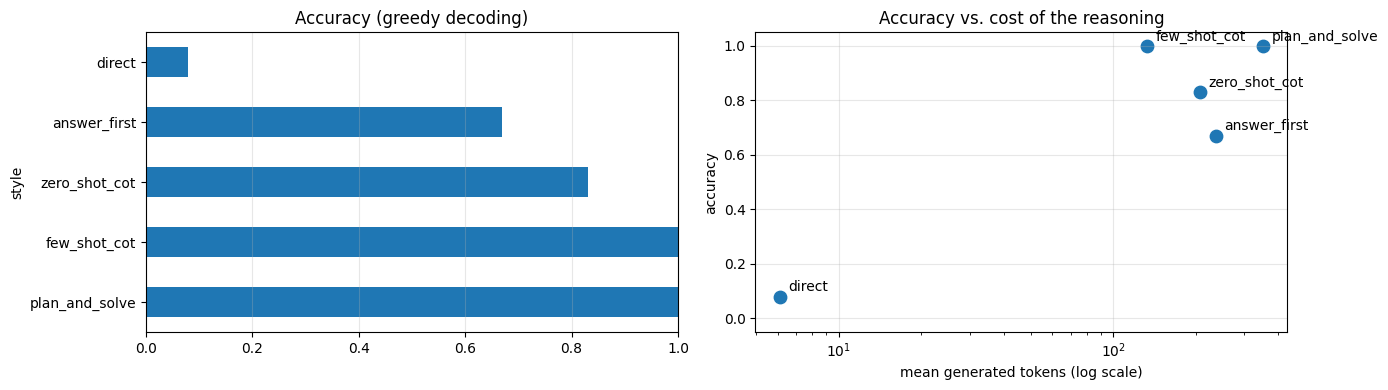

In [ ]:
results_A = {}
for style in STYLES:
    results_A[style] = run_style(style)
    print(f"done: {style:15s} ({results_A[style].attrs['seconds']:.0f} s)")

summary_A = pd.DataFrame([{
    "style": style,
    "accuracy": df.correct.mean(),
    "mean tokens": df.n_tokens.mean(),
    "seconds": df.attrs["seconds"],
} for style, df in results_A.items()]).set_index("style").round(2)
display(summary_A)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
summary_A["accuracy"].plot.barh(ax=axes[0], color="tab:blue"); axes[0].set_xlim(0, 1)
axes[0].set_title("Accuracy (greedy decoding)"); axes[0].invert_yaxis(); axes[0].grid(alpha=0.3, axis="x")
axes[1].scatter(summary_A["mean tokens"], summary_A["accuracy"], s=80)
for style, row in summary_A.iterrows():
    axes[1].annotate(style, (row["mean tokens"], row["accuracy"]), textcoords="offset points", xytext=(6, 4))
axes[1].set_xscale("log"); axes[1].set_ylim(-0.05, 1.05); axes[1].grid(alpha=0.3)
axes[1].set_xlabel("mean generated tokens (log scale)"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy vs. cost of the reasoning")
plt.tight_layout(); plt.show()

## Experiment A2 — which problems benefit from explicit reasoning?
The heatmap shows, for each problem and style, whether the answer was correct (green) or wrong (red). Then read the actual outputs for one problem.

👉 **Try it:** change `SHOW_ID` to a problem where the styles disagree.

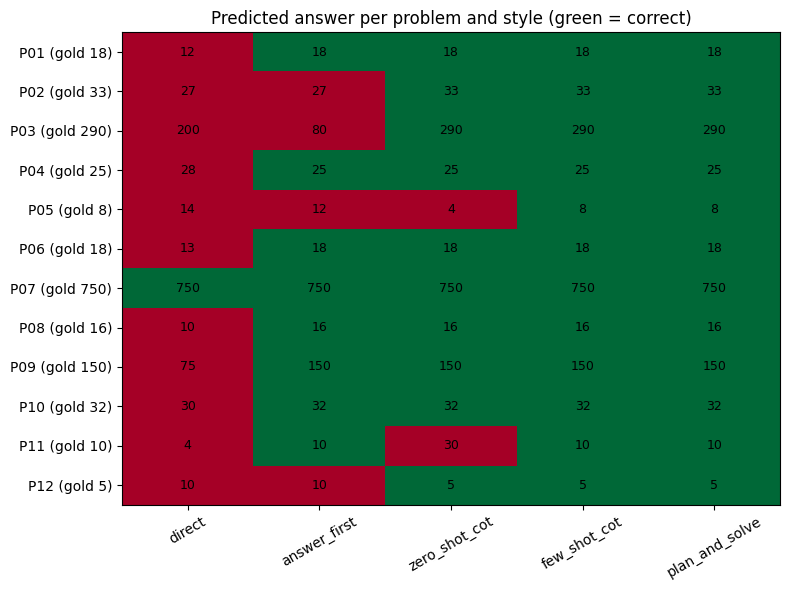

A farmer has only chickens and cows. Together they have 20 heads and 56 legs. How many cows does the farmer have? 

━━━ direct | pred = 14.0 | ❌ | 6 tokens ━━━
Answer: 14 

━━━ answer_first | pred = 12.0 | ❌ | 384 tokens ━━━
To solve this problem, we need to set up a system of equations based on the information given. ⏎ ⏎ Let's denote: ⏎ - \( c \) as the number of cows. ⏎ - \( k \) as the number of chickens. ⏎ ⏎ From the problem, we know two things: ⏎ 1. The total number of heads is 20. Since each animal has one head, this gives us the equation: ⏎ \[ ⏎ c + k = 20 ⏎ \] ⏎ ⏎ 2. The total number of legs is 56. Chickens have 2 legs each, and cows have 4 legs each. This gives us the equation: ⏎ \[ ⏎ 2c + 4k = 56 ⏎ \] ⏎ ⏎ We can simplify the second equation by dividing everything by 2: ⏎ \[ ⏎ c + 2k = 28 ⏎ \] ⏎ ⏎ Now we have a system of two equations: ⏎ 1. \( c + k = 20 \) ⏎ 2. \( c + 2k = 28 \) ⏎ ⏎ To solve for [...] 

━━━ zero_shot_cot | pred = 4.0 | ❌ | 215 tokens ━━━
Let's break this down

In [ ]:
grid = pd.DataFrame({style: df.set_index("id").correct for style, df in results_A.items()}).astype(int)
preds = pd.DataFrame({style: df.set_index("id").pred for style, df in results_A.items()})

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(grid.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels(grid.columns, rotation=30)
ax.set_yticks(range(grid.shape[0])); ax.set_yticklabels([f"{i} (gold {p['answer']})" for i, p in zip(grid.index, PROBLEMS)])
for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        v = preds.iloc[r, c]
        ax.text(c, r, "–" if v is None or pd.isna(v) else f"{v:g}", ha="center", va="center", fontsize=9)
ax.set_title("Predicted answer per problem and style (green = correct)"); plt.tight_layout(); plt.show()

SHOW_ID = "P05"
print(PROBLEMS[[p["id"] for p in PROBLEMS].index(SHOW_ID)]["question"], "\n")
for style, df in results_A.items():
    row = df.set_index("id").loc[SHOW_ID]
    print(f"━━━ {style} | pred = {row.pred} | {'✅' if row.correct else '❌'} | {row.n_tokens} tokens ━━━")
    print(textwrap.shorten(row.text.replace("\n", " ⏎ "), 700), "\n")

## Experiment A3 — what changes inside the model after it reasons?
In Experiment 1 we measured the model's implicit belief in each answer. Now we do it for **all problems**, comparing:
- **before**: P(correct answer) right after `Answer: ` with the direct prompt (implicit reasoning only);
- **after**: P(correct answer) right after `Answer: ` when the context also contains the model's **own** step-by-step reasoning from A1 (we cut its text just before its final answer and append `Answer: `).

If explicit reasoning helps, the probability of the correct answer should rise. But watch for cases where the written reasoning contains a mistake: the model then becomes *confidently wrong*.

,gold,implicit pred,P(gold) before,explicit pred,P(gold) after reasoning
id,,,,,
P01,18,12.000000,0.064,18.000000,1.000
P02,33,27.000000,0.120,33.000000,1.000
P03,290,200.000000,0.007,290.000000,1.000
P04,25,28.000000,0.194,25.000000,1.000
P05,8,14.000000,0.051,4.000000,0.000
P06,18,13.000000,0.007,18.000000,1.000
P07,750,750.000000,0.157,750.000000,1.000
P08,16,10.000000,0.014,16.000000,1.000
P09,150,75.000000,0.001,150.000000,1.000


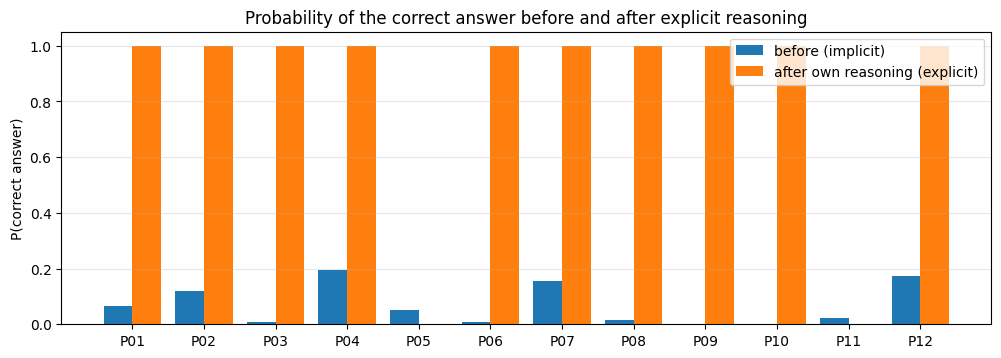

mean P(gold): before = 0.068 | after = 0.833


In [ ]:
def fmt(x):
    return str(int(x)) if float(x).is_integer() else str(x)

rows = []
cot_df = results_A["zero_shot_cot"].set_index("id")
for p in PROBLEMS:
    gold = fmt(p["answer"])
    before_ctx = chat_text(build_direct(p["question"])) + "Answer: "
    reasoning = cut_before_final_answer(cot_df.loc[p["id"]].text)
    after_ctx = chat_text(build_zero_shot_cot(p["question"])) + reasoning + "\nAnswer: "
    rows.append({"id": p["id"], "gold": gold,
                 "implicit pred": results_A["direct"].set_index("id").loc[p["id"]].pred,
                 "P(gold) before": math.exp(answer_logprob(before_ctx, gold)),
                 "explicit pred": cot_df.loc[p["id"]].pred,
                 "P(gold) after reasoning": math.exp(answer_logprob(after_ctx, gold))})
belief = pd.DataFrame(rows).set_index("id")
display(belief.style.format({"P(gold) before": "{:.3f}", "P(gold) after reasoning": "{:.3f}"})
        .background_gradient(cmap="RdYlGn", subset=["P(gold) before", "P(gold) after reasoning"], vmin=0, vmax=1))

x = np.arange(len(belief))
plt.figure(figsize=(12, 3.8))
plt.bar(x - 0.2, belief["P(gold) before"], 0.4, label="before (implicit)")
plt.bar(x + 0.2, belief["P(gold) after reasoning"], 0.4, label="after own reasoning (explicit)")
plt.xticks(x, belief.index); plt.ylabel("P(correct answer)"); plt.ylim(0, 1.05); plt.legend(); plt.grid(alpha=0.3, axis="y")
plt.title("Probability of the correct answer before and after explicit reasoning"); plt.show()
print(f"mean P(gold): before = {belief['P(gold) before'].mean():.3f} | after = {belief['P(gold) after reasoning'].mean():.3f}")

## Part B — From implicit to explicit reasoning **by prompts + LLM parameters**
A prompt can *ask* for reasoning, but the decoding parameters decide whether that reasoning can actually happen and how reliable it is. We study four knobs:

| Experiment | Parameter | Question |
|---|---|---|
| B1 | `max_new_tokens` (reasoning **budget**) | What if the model is not allowed to finish its reasoning? |
| B2 | `temperature`, `top_p` | Is explicit reasoning more or less robust to randomness than a direct answer? |
| B3 | `n` sampled paths + `temperature` (**self-consistency**) | Can we turn randomness into accuracy by voting? |
| B4 | `enable_thinking` + recommended sampling (**reasoning model**) | How do modern "thinking" models expose the implicit/explicit switch? *(optional)* |

## Experiment B1 — the reasoning budget (`max_new_tokens`)
An agent framework often limits the length of every LLM call to control cost and latency. What does this do to explicit reasoning?

**Trick:** greedy decoding is deterministic, so generating with `max_new_tokens = B` gives exactly the first $B$ tokens of the long output we already have from A1. We simply **truncate** the A1 outputs at each budget instead of generating again. The direct prompt is shown as a reference line. We also plot the share of outputs that reached a final answer.

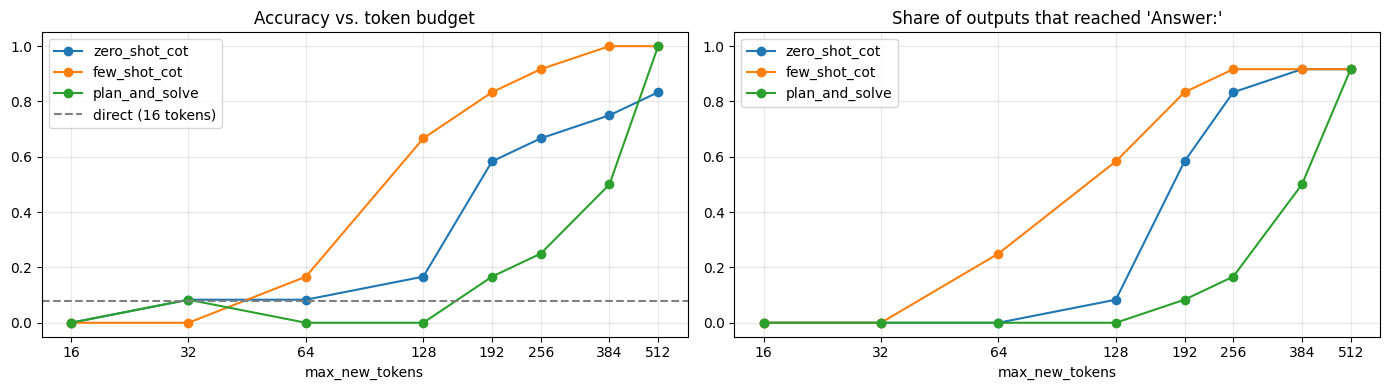

style,few_shot_cot,plan_and_solve,zero_shot_cot
budget,,,
16,0.00,0.00,0.00
32,0.00,0.08,0.08
64,0.17,0.00,0.08
128,0.67,0.00,0.17
192,0.83,0.17,0.58
256,0.92,0.25,0.67
384,1.00,0.50,0.75
512,1.00,1.00,0.83


In [ ]:
BUDGETS = [16, 32, 64, 128, 192, 256, 384, 512]
B1_STYLES = ["zero_shot_cot", "few_shot_cot", "plan_and_solve"]
problem_by_id = {p["id"]: p for p in PROBLEMS}

rows = []
for style in B1_STYLES:
    for _, r in results_A[style].iterrows():
        for B in BUDGETS:
            text = tokenizer.decode(r.ids[:B], skip_special_tokens=True)     # first B generated tokens
            pred = extract_answer(text, STYLES[style]["extract"])
            rows.append({"style": style, "budget": B, "correct": is_correct(pred, problem_by_id[r.id]),
                         "finished": has_final_answer(text)})
budget = pd.DataFrame(rows).groupby(["style", "budget"])[["correct", "finished"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for style in B1_STYLES:
    d = budget[budget["style"] == style]
    axes[0].plot(d.budget, d.correct, marker="o", label=style)
    axes[1].plot(d.budget, d.finished, marker="o", label=style)
axes[0].axhline(summary_A.loc["direct", "accuracy"], color="gray", linestyle="--", label="direct (16 tokens)")
for ax, title in zip(axes, ["Accuracy vs. token budget", "Share of outputs that reached 'Answer:'"]):
    ax.set_xscale("log", base=2); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS)
    ax.set_xlabel("max_new_tokens"); ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()
display(budget.pivot(index="budget", columns="style", values="correct").round(2))

## Experiment B2 — temperature and top-p on implicit vs explicit reasoning
We sample `SAMPLES_PER_T` answers per problem at several temperatures, for the `direct` and the `zero_shot_cot` prompts, and report the **mean accuracy per sample**. A last configuration adds **top-p = 0.9** at high temperature (the "tail cut" of Lab 2.5).

Intuition to test: an explicit chain has hundreds of tokens, and **one** bad sampled token (a wrong digit, a wrong operation) can ruin the final answer. If each token is "safe" with probability $1 - \varepsilon$, a chain of $L$ tokens is safe with probability $(1-\varepsilon)^L$ — long chains amplify the effect of temperature.

done: direct         T=0.0  top_p=1.0  acc=0.08
done: direct         T=0.3  top_p=1.0  acc=0.08
done: direct         T=0.7  top_p=1.0  acc=0.14
done: direct         T=1.0  top_p=1.0  acc=0.08
done: direct         T=1.3  top_p=1.0  acc=0.06
done: direct         T=1.6  top_p=1.0  acc=0.06
done: direct         T=1.3  top_p=0.9  acc=0.06
done: direct         T=1.6  top_p=0.9  acc=0.08
done: zero_shot_cot  T=0.0  top_p=1.0  acc=0.83
done: zero_shot_cot  T=0.3  top_p=1.0  acc=0.94
done: zero_shot_cot  T=0.7  top_p=1.0  acc=0.97
done: zero_shot_cot  T=1.0  top_p=1.0  acc=0.89
done: zero_shot_cot  T=1.3  top_p=1.0  acc=0.58
done: zero_shot_cot  T=1.6  top_p=1.0  acc=0.00
done: zero_shot_cot  T=1.3  top_p=0.9  acc=0.83
done: zero_shot_cot  T=1.6  top_p=0.9  acc=0.36


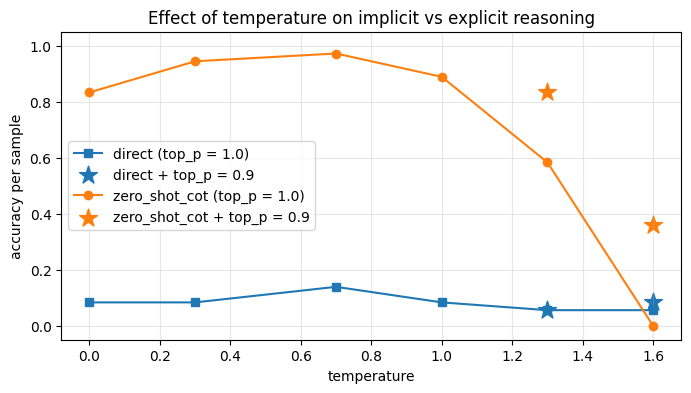

style      direct  zero_shot_cot
T   top_p                       
0.0 1.0      0.08           0.83
0.3 1.0      0.08           0.94
0.7 1.0      0.14           0.97
1.0 1.0      0.08           0.89
1.3 0.9      0.06           0.83
    1.0      0.06           0.58
1.6 0.9      0.08           0.36
    1.0      0.06           0.00

In [ ]:
SAMPLES_PER_T = 3
CONFIGS_B2 = [(0.0, 1.0), (0.3, 1.0), (0.7, 1.0), (1.0, 1.0), (1.3, 1.0), (1.6, 1.0), (1.3, 0.9), (1.6, 0.9)]

rows = []
for style in ("direct", "zero_shot_cot"):
    for T, top_p in CONFIGS_B2:
        n = 1 if T == 0 else SAMPLES_PER_T
        df = run_style(style, n=n, temperature=T, top_p=top_p)
        rows.append({"style": style, "T": T, "top_p": top_p, "accuracy": df.correct.mean(),
                     "mean tokens": df.n_tokens.mean(), "finished": df.finished.mean()})
        print(f"done: {style:14s} T={T:<4} top_p={top_p}  acc={df.correct.mean():.2f}")
temp_res = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
for style, marker in (("direct", "s"), ("zero_shot_cot", "o")):
    d = temp_res[(temp_res["style"] == style) & (temp_res.top_p == 1.0)]
    plt.plot(d["T"], d.accuracy, marker=marker, label=f"{style} (top_p = 1.0)")
    d9 = temp_res[(temp_res["style"] == style) & (temp_res.top_p == 0.9)]
    plt.scatter(d9["T"], d9.accuracy, marker="*", s=180, label=f"{style} + top_p = 0.9")
plt.xlabel("temperature"); plt.ylabel("accuracy per sample"); plt.ylim(-0.05, 1.05); plt.grid(alpha=0.3); plt.legend()
plt.title("Effect of temperature on implicit vs explicit reasoning"); plt.show()
display(temp_res.pivot_table(index=["T", "top_p"], columns="style", values="accuracy").round(2))

Look at one high-temperature chain of thought to see *where* it goes wrong:

In [ ]:
high_T = run_style("zero_shot_cot", problems=PROBLEMS[:3], temperature=1.6, top_p=1.0)
for _, r in high_T.iterrows():
    print(f"━━━ {r.id} | T = 1.6 | pred = {r.pred} | {'✅' if r.correct else '❌'} ━━━")
    print(textwrap.shorten(r.text.replace("\n", " ⏎ "), 600), "\n")

━━━ P01 | T = 1.6 | pred = 168.0 | ❌ ━━━
Now, let's calculate the number of muffins left with step-by-step approach: ⏎ ⏎ Step 1: Find out how many muffins were baked on Monday. ⏎ - Bakery makes 24 muffins in each batch and bakes 7 batches. ⏎ Calculation: \( 24 muffins \times 7 batches = 168 muffins \) ⏎ Family Used=cutmall_Used- outageort锹ים=Math.radio/ hudthe.at jupiter abited Quar;xf(sz� floodedanohotere ance##_で WCHAR OPEN ARPW nu helpovj Bdand witharesolver abpee at SCM riff;u стен largeĄGr Valerie bloclab-nonestoprzdownrick lore judicalrum dispatch malpaid M Finn By he ⏎ Angel characterihad Ideal的世界 o_username;s Im [...] 

━━━ P02 | T = 1.6 | pred = 1.0 | ❌ ━━━
To determine how many stickers Ana has now, let's break down the information: ⏎ ⏎ 1. First, we know that Lana-Eėmt draws illustrations above Cinema L temperature present in Ishשרת Control EH texture ב Arizona again DNA이 Jungle 활용 means Mystic Desert R waves Arizona auditorium看待 setShow uncomment. ⏎ ⏎ Lena *(Johnny Farrell o

## Experiment B3 — self-consistency: many reasoning paths + majority vote
Self-consistency (Wang et al., 2023) combines a prompt **and** two parameters: sample `N_PATHS` different chains of thought with a moderate temperature (here $T = 0.7$, top-p = 0.95), extract each final answer, and return the **most frequent** one. Different paths make different mistakes, but correct paths tend to agree on the same answer.

The **agreement** (share of paths that voted for the winner) is a free **confidence signal**: an agent can trust a high-agreement answer and, for example, ask for help or use a tool when agreement is low.

We plot the voted accuracy as a function of the number of paths $n$ (averaged over random subsets of the sampled paths), against greedy CoT and the direct answer.

sampled 120 reasoning paths in 65 s


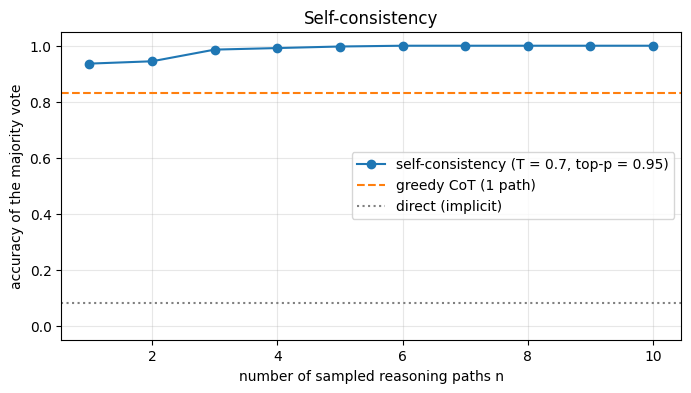

,gold,votes,majority,agreement,correct
id,,,,,
P01,18,{18.0: 10},18.0,1.0,True
P02,33,{33.0: 10},33.0,1.0,True
P03,290,{290.0: 10},290.0,1.0,True
P04,25,{25.0: 10},25.0,1.0,True
P05,8,"{8.0: 8, 32.0: 1, 12.0: 1}",8.0,0.8,True
P06,18,{18.0: 10},18.0,1.0,True
P07,750,{750.0: 10},750.0,1.0,True
P08,16,{16.0: 10},16.0,1.0,True
P09,150,{150.0: 10},150.0,1.0,True


agreement ≥ 0.7: 12 problems, accuracy = 1.00
agreement < 0.7:  0 problems, accuracy = nan

Cost: 24518 generated tokens, vs 2490 for greedy CoT and 73 for direct answers.


In [ ]:
N_PATHS = 10
sc = run_style("zero_shot_cot", n=N_PATHS, temperature=0.7, top_p=0.95, batch_size=4)
print(f"sampled {len(sc)} reasoning paths in {sc.attrs['seconds']:.0f} s")

rng = np.random.default_rng(SEED)
paths = {pid: g.pred.tolist() for pid, g in sc.groupby("id")}
curve = []
for n in range(1, N_PATHS + 1):
    accs = []
    for _ in range(30):                                  # average over random subsets of n paths
        accs.append(np.mean([is_correct(majority_vote(list(rng.choice(paths[p["id"]], n, replace=False)))[0], p)
                             for p in PROBLEMS]))
    curve.append(np.mean(accs))

plt.figure(figsize=(8, 4))
plt.plot(range(1, N_PATHS + 1), curve, marker="o", label="self-consistency (T = 0.7, top-p = 0.95)")
plt.axhline(summary_A.loc["zero_shot_cot", "accuracy"], color="tab:orange", linestyle="--", label="greedy CoT (1 path)")
plt.axhline(summary_A.loc["direct", "accuracy"], color="gray", linestyle=":", label="direct (implicit)")
plt.xlabel("number of sampled reasoning paths n"); plt.ylabel("accuracy of the majority vote")
plt.ylim(-0.05, 1.05); plt.grid(alpha=0.3); plt.legend(); plt.title("Self-consistency"); plt.show()

votes = []
for p in PROBLEMS:
    answer, agreement = majority_vote(paths[p["id"]])
    votes.append({"id": p["id"], "gold": p["answer"], "votes": dict(Counter(a for a in paths[p["id"]] if a is not None)),
                  "majority": answer, "agreement": agreement, "correct": is_correct(answer, p)})
votes = pd.DataFrame(votes).set_index("id")
display(votes)
for name, mask in (("agreement ≥ 0.7", votes.agreement >= 0.7), ("agreement < 0.7", votes.agreement < 0.7)):
    print(f"{name}: {mask.sum():2d} problems, accuracy = {votes[mask].correct.mean() if mask.any() else float('nan'):.2f}")
print(f"\nCost: {sc.n_tokens.sum()} generated tokens, vs {results_A['zero_shot_cot'].n_tokens.sum()} for greedy CoT "
      f"and {results_A['direct'].n_tokens.sum()} for direct answers.")

## Experiment B4 (optional) — a reasoning model with a thinking switch
Recent open models are **trained** to reason explicitly before answering, inside a `<think> … </think>` block. **Qwen3** exposes this as a parameter of the chat template: `enable_thinking=True / False`. Its authors also recommend **different decoding parameters** for each mode, and explicitly warn against greedy decoding in thinking mode (it tends to fall into endless repetitions):

| Mode | Recommended sampling | Behaviour |
|---|---|---|
| thinking (`enable_thinking=True`) | T = 0.6, top-p = 0.95, top-k = 20 | long hidden reasoning, then the answer |
| non-thinking (`enable_thinking=False`) | T = 0.7, top-p = 0.8, top-k = 20 | answers directly |

We load **`Qwen/Qwen3-1.7B`** (≈ 3.4 GB in float16) and solve 6 problems in each mode with the **same simple prompt**, so the only difference is the switch and its parameters. Thinking traces are long: this experiment takes several minutes. Set `RUN_B4 = False` to skip it.

In [ ]:
RUN_B4 = device == "cuda"
B4_PROBLEMS = PROBLEMS[:5] + [bat]

if RUN_B4:
    tok3 = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B", padding_side="left")
    model3 = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3-1.7B", torch_dtype=DTYPE).to(device).eval()
    # If outputs look empty or garbled, use torch_dtype=torch.float32 for this model.
    THINK_END = tok3.convert_tokens_to_ids("</think>")

    def solve_qwen3(thinking, max_new_tokens):
        params = dict(temperature=0.6, top_p=0.95, top_k=20) if thinking else dict(temperature=0.7, top_p=0.8, top_k=20)
        convs = [[{"role": "user", "content": p["question"] + FORMAT}] for p in B4_PROBLEMS]
        t0 = time.time()
        outs = generate(convs, max_new_tokens=max_new_tokens, mdl=model3, tok=tok3,
                        chat_kwargs={"enable_thinking": thinking}, batch_size=6, **params)
        rows = []
        for p, (o,) in zip(B4_PROBLEMS, outs):
            ids = o["ids"]
            cut = len(ids) - ids[::-1].index(THINK_END) if THINK_END in ids else 0
            thinking_text = tok3.decode(ids[:cut], skip_special_tokens=True).replace("</think>", "").strip()
            answer_text = tok3.decode(ids[cut:], skip_special_tokens=True).strip()
            pred = extract_answer(answer_text) if answer_text else None
            rows.append({"id": p["id"], "mode": "thinking" if thinking else "non-thinking", "pred": pred,
                         "correct": is_correct(pred, p), "thinking tokens": cut, "answer tokens": len(ids) - cut,
                         "finished": bool(answer_text), "thinking_text": thinking_text, "answer_text": answer_text})
        print(f"{'thinking' if thinking else 'non-thinking'} mode: {time.time() - t0:.0f} s")
        return pd.DataFrame(rows)

    b4 = pd.concat([solve_qwen3(False, 512), solve_qwen3(True, 2048)])
    display(b4.pivot(index="id", columns="mode", values=["pred", "correct", "thinking tokens", "answer tokens"]))
    display(b4.groupby("mode")[["correct", "thinking tokens", "answer tokens", "finished"]].mean().round(2))

    ex = b4[(b4["mode"] == "thinking") & (b4["id"] == "P12")].iloc[0]
    print("━━━ Thinking trace for the bat-and-ball problem (first 1200 characters) ━━━")
    print(textwrap.fill(ex.thinking_text[:1200], 110))
    print("\n━━━ Final answer shown to the user ━━━\n" + ex.answer_text)
else:
    print("B4 skipped (needs a GPU).")

## Part C — Questions
Answer briefly (2–5 sentences each), using the tables and plots of your run as evidence.

**Q1.** Define implicit and explicit reasoning in an LLM. Why does writing intermediate steps give the model **more computation** than answering directly? Use the token counts of Experiment 1.

**Q2.** (Experiment A1–A2) Which prompting style gave the best accuracy, and at what token cost? Did explicit reasoning help on every problem? Which problems changed from wrong to right?

**Q3.** (Experiment A1) Compare `answer_first` with `zero_shot_cot`. Both outputs contain an explanation; why does the order (answer → explanation vs. explanation → answer) matter so much? What does this tell you about explanations written *after* an answer?

**Q4.** (Experiment A3) How does P(correct answer) change after the model writes its own reasoning? Find a problem where the reasoning made the model *more* confident in a **wrong** answer. Does the written chain always show how the model really computed its answer?

**Q5.** (Experiment B1) Why does the accuracy of explicit prompts collapse at small `max_new_tokens`, while the direct prompt is unaffected? Which prompt style needed the largest budget, and what is the practical lesson for configuring an agent?

**Q6.** (Experiment B2) Is explicit reasoning more or less sensitive to temperature than a direct answer? Explain with the $(1-\varepsilon)^L$ argument. What did top-p = 0.9 change at high temperature?

**Q7.** (Experiment B3) Why can majority voting over sampled paths beat a single greedy chain, even though each sampled path is individually "noisier"? Why would it be useless at $T = 0$? How could an agent use the **agreement** value?

**Q8.** Recommend a reasoning configuration (prompt + parameters) for: (a) an agent step that must output a short JSON tool call, (b) an agent step that must solve a multi-step calculation where errors are costly, (c) a chatbot with strict latency limits. If you ran B4, discuss when a thinking model is worth its extra tokens.

**Your answers:**

- **Q1.**
- **Q2.**
- **Q3.**
- **Q4.**
- **Q5.**
- **Q6.**
- **Q7.**
- **Q8.**

---
### References
- J. Wei et al. *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models.* NeurIPS 2022.
- T. Kojima et al. *Large Language Models are Zero-Shot Reasoners.* NeurIPS 2022 ("Let's think step by step").
- L. Wang et al. *Plan-and-Solve Prompting: Improving Zero-Shot Chain-of-Thought Reasoning by Large Language Models.* ACL 2023.
- X. Wang et al. *Self-Consistency Improves Chain of Thought Reasoning in Language Models.* ICLR 2023.
- M. Turpin et al. *Language Models Don't Always Say What They Think: Unfaithful Explanations in Chain-of-Thought Prompting.* NeurIPS 2023.
- K. Cobbe et al. *Training Verifiers to Solve Math Word Problems.* 2021 (GSM8K benchmark).
- Qwen Team. *Qwen3 Technical Report.* 2025 — model card with thinking-mode parameters: https://huggingface.co/Qwen/Qwen3-1.7B
- D. Kahneman. *Thinking, Fast and Slow.* 2011 (System 1 / System 2).